# Sales and E-Commerce Performance Analytics Dashboard
## Final Data Analytics Project — Week 6 Internship Assignment

- **Student Name:** Tushar Marathe
- **Internship Organization:** Internova
- **Internship Domain:** Data Analytics
- **Total Marks:** 100 | **Duration:** 7 Days
- **Date:** October 2026

---

### Project Overview & Objectives
This project is an end-to-end exploratory data analysis and business intelligence capstone investigating e-commerce retail transactions.
Key objectives:
1. Load, validate, clean, and feature-engineer raw transaction data.
2. Calculate business KPIs: Total Sales, Total Profit, Profit Margin %, Units Sold, and Average Order Value (AOV).
3. Conduct univariate, bivariate, and multivariate analysis across product categories, sub-categories, regions, and customer segments.
4. Uncover the quantitative relationship between discounting depth and net profitability.
5. Provide actionable, data-driven business recommendations backed by empirical metrics.

> **Data Disclosure & Methodology:** The dataset analyzed in this project is synthetically generated using calibrated statistical distributions modeled after the public Tableau Sample Superstore schema (seed=42). All metrics, findings, and visualizations reflect this dataset for rigorous academic and evaluation purposes.

## 1. Environment Setup & Data Loading
Import required Python libraries for data manipulation, numerical calculations, statistical analysis, and visual charting.

In [1]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 110

# Locate and load cleaned dataset
data_candidates = [
    os.path.join('..', 'data', 'cleaned_sales.csv'),
    os.path.join('data', 'cleaned_sales.csv'),
    os.path.join('..', 'data', 'processed', 'cleaned_sales.csv')
]
data_path = next((p for p in data_candidates if os.path.exists(p)), 'data/cleaned_sales.csv')

df = pd.read_csv(data_path)
df['Order Date'] = pd.to_datetime(df['Order Date'])
if 'Ship Date' in df.columns:
    df['Ship Date'] = pd.to_datetime(df['Ship Date'])

print(f"Dataset successfully loaded from: {data_path}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date Range: {df['Order Date'].min().strftime('%Y-%m-%d')} to {df['Order Date'].max().strftime('%Y-%m-%d')}")

Dataset successfully loaded from: data\cleaned_sales.csv
Dimensions: 9,994 rows x 26 columns
Date Range: 2020-01-01 to 2023-12-31


## 2. Initial Data Inspection
Inspecting the first and last records, schema dimensions, column data types, and memory consumption.

In [2]:
# Display first 5 records
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Quarter,Profit Margin %
0,4123,CA-2021-0003914,2021-01-06,2021-01-11,Second Class,CUST-00264,Customer CUST-00264,Home Office,United States,St. Louis,Minnesota,56930,Central,Prod-OFF-STO-0013,Office Supplies,Storage,Storage Item 013,680.25,13,0.15,10.84,2021,1,Jan,1,1.59
1,4066,CA-2020-0003873,2020-11-15,2020-11-21,Standard Class,CUST-00118,Customer CUST-00118,Consumer,United States,Boston,Vermont,25398,East,Prod-FUR-FUR-0002,Furniture,Furnishings,Furnishings Item 002,147.07,4,0.10,4.22,2020,11,Nov,4,2.87
2,1732,CA-2023-0002222,2023-04-01,2023-04-08,Standard Class,CUST-00147,Customer CUST-00147,Corporate,United States,Denver,Oregon,87367,West,Prod-TEC-PHO-0007,Technology,Phones,Phones Item 007,1840.21,4,0.10,105.43,2023,4,Apr,2,5.73
3,4741,CA-2020-0004350,2020-08-11,2020-08-20,Standard Class,CUST-00413,Customer CUST-00413,Corporate,United States,Jacksonville,South Carolina,69450,South,Prod-TEC-MAC-0006,Technology,Machines,Machines Item 006,2971.44,3,0.50,-1387.59,2020,8,Aug,3,-46.70
4,6392,CA-2021-0005464,2021-03-05,2021-03-14,Standard Class,CUST-00008,Customer CUST-00008,Consumer,United States,Philadelphia,New York,26803,East,Prod-OFF-APP-0011,Office Supplies,Appliances,Appliances Item 011,933.85,14,0.30,-171.85,2021,3,Mar,1,-18.40


In [3]:
# Display last 5 records
df.tail(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Quarter,Profit Margin %
9989,5735,CA-2023-0005022,2023-05-29,2023-06-04,Second Class,CUST-00029,Customer CUST-00029,Consumer,United States,Chicago,Iowa,26171,Central,Prod-TEC-MAC-0011,Technology,Machines,Machines Item 011,941.18,1,0.0,142.74,2023,5,May,2,15.17
9990,5192,CA-2021-0004644,2021-08-06,2021-08-06,Same Day,CUST-00499,Customer CUST-00499,Corporate,United States,Philadelphia,Pennsylvania,21087,East,Prod-FUR-CHA-0006,Furniture,Chairs,Chairs Item 006,1278.16,5,0.0,172.20,2021,8,Aug,3,13.47
9991,5391,CA-2021-0004774,2021-10-18,2021-10-18,Same Day,CUST-00539,Customer CUST-00539,Consumer,United States,San Francisco,Utah,81673,West,Prod-OFF-PAP-0016,Office Supplies,Paper,Paper Item 016,435.56,10,0.0,146.03,2021,10,Oct,4,33.53
9992,861,CA-2020-0001607,2020-03-15,2020-03-25,Standard Class,CUST-00171,Customer CUST-00171,Home Office,United States,Omaha,Texas,55624,Central,Prod-TEC-PHO-0004,Technology,Phones,Phones Item 004,4342.25,8,0.0,867.36,2020,3,Mar,1,19.97
9993,7271,CA-2020-0006087,2020-06-16,2020-06-22,Second Class,CUST-00668,Customer CUST-00668,Consumer,United States,Portland,Idaho,14036,West,Prod-TEC-PHO-0008,Technology,Phones,Phones Item 008,1798.14,4,0.0,353.60,2020,6,Jun,2,19.66


In [4]:
# Column names and data types summary
dtypes_df = pd.DataFrame({
    'Column Name': df.columns,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Data Type': df.dtypes.astype(str).values
})
print(f"Total Columns: {len(df.columns)}")
dtypes_df

Total Columns: 26


,Column Name,Non-Null Count,Null Count,Data Type
0,Row ID,9994,0,int64
1,Order ID,9994,0,str
2,Order Date,9994,0,datetime64[us]
3,Ship Date,9982,12,datetime64[us]
4,Ship Mode,9994,0,str
5,Customer ID,9994,0,str
6,Customer Name,9994,0,str
7,Segment,9994,0,str
8,Country,9994,0,str
9,City,9994,0,str


## 3. Data Quality, Missing Values & Duplicate Verification
Verify that the cleaning pipeline eliminated duplicate records and appropriately preserved business-valid null values (such as unshipped orders).

In [5]:
# Missing Value Analysis
missing_cnt = df.isnull().sum()
missing_pct = (missing_cnt / len(df) * 100).round(2)
missing_table = pd.DataFrame({'Missing Records': missing_cnt, 'Missing %': missing_pct})
missing_table = missing_table[missing_table['Missing Records'] > 0]

print("--- Missing Values Report ---")
if len(missing_table) == 0:
    print("No missing values detected.")
else:
    print(missing_table)
    print("
Note: Null Ship Dates correspond to currently pending/unshipped orders and are intentionally retained.")


Execution error: unterminated string literal (detected at line 12) (<unknown>, line 12)

In [6]:
# Duplicate Record Analysis
exact_dups = df.duplicated().sum()
order_dups = df.duplicated(subset=['Order ID', 'Product ID']).sum()
print(f"Exact Duplicate Rows: {exact_dups}")
print(f"Duplicate (Order ID + Product ID) pairs: {order_dups}")
assert exact_dups == 0, "Duplicate records found!"
print("Data integrity check passed: 0 duplicate rows present.")

Exact Duplicate Rows: 0
Duplicate (Order ID + Product ID) pairs: 8
Data integrity check passed: 0 duplicate rows present.


## 4. Descriptive Summary Statistics
Examine parametric and non-parametric central tendencies, dispersion, and range for all numerical business variables.

In [7]:
num_cols = ['Sales', 'Profit', 'Quantity', 'Discount', 'Profit Margin %']
desc_stats = df[num_cols].describe().T
desc_stats['median'] = df[num_cols].median()
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['skewness'] = df[num_cols].skew()
desc_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'IQR', 'skewness']].round(2)

,count,mean,std,min,25%,median,75%,max,IQR,skewness
Sales,9994.0,3319.09,6317.44,3.38,267.79,962.62,3257.06,61198.74,2989.28,3.72
Profit,9994.0,364.48,2034.98,-7515.12,-75.31,14.74,134.61,24133.49,209.91,5.12
Quantity,9994.0,7.46,4.04,1.00,4.00,7.00,11.00,14.00,7.00,0.01
Discount,9994.0,0.14,0.17,0.00,0.00,0.10,0.20,0.80,0.20,1.55
Profit Margin %,9994.0,1.34,23.36,-113.32,-9.63,4.58,17.73,48.47,27.36,-1.01


## 5. Outlier Detection (Tukey's IQR Method)
Detect extreme observations across Sales and Profit distributions to differentiate legitimate high-value enterprise orders from potential data errors.

In [8]:
outlier_summary = []
for col in ['Sales', 'Profit']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    extreme_upper = Q3 + 3.0 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    extreme_outliers = df[(df[col] < (Q1 - 3.0 * IQR)) | (df[col] > extreme_upper)]
    
    outlier_summary.append({
        'Variable': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round(len(outliers) / len(df) * 100, 2),
        'Extreme Outliers': len(extreme_outliers)
    })

pd.DataFrame(outlier_summary)

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %,Extreme Outliers
0,Sales,267.79,3257.06,2989.28,-4216.13,7740.98,1084,10.85,690
1,Profit,-75.31,134.61,209.91,-390.18,449.47,2498,24.99,1732


## 6. Univariate Analysis: Distributions of Core Numerical Features
Visualize the distribution, skewness, and frequency histograms for Sales, Profit, Quantity, and Discount.

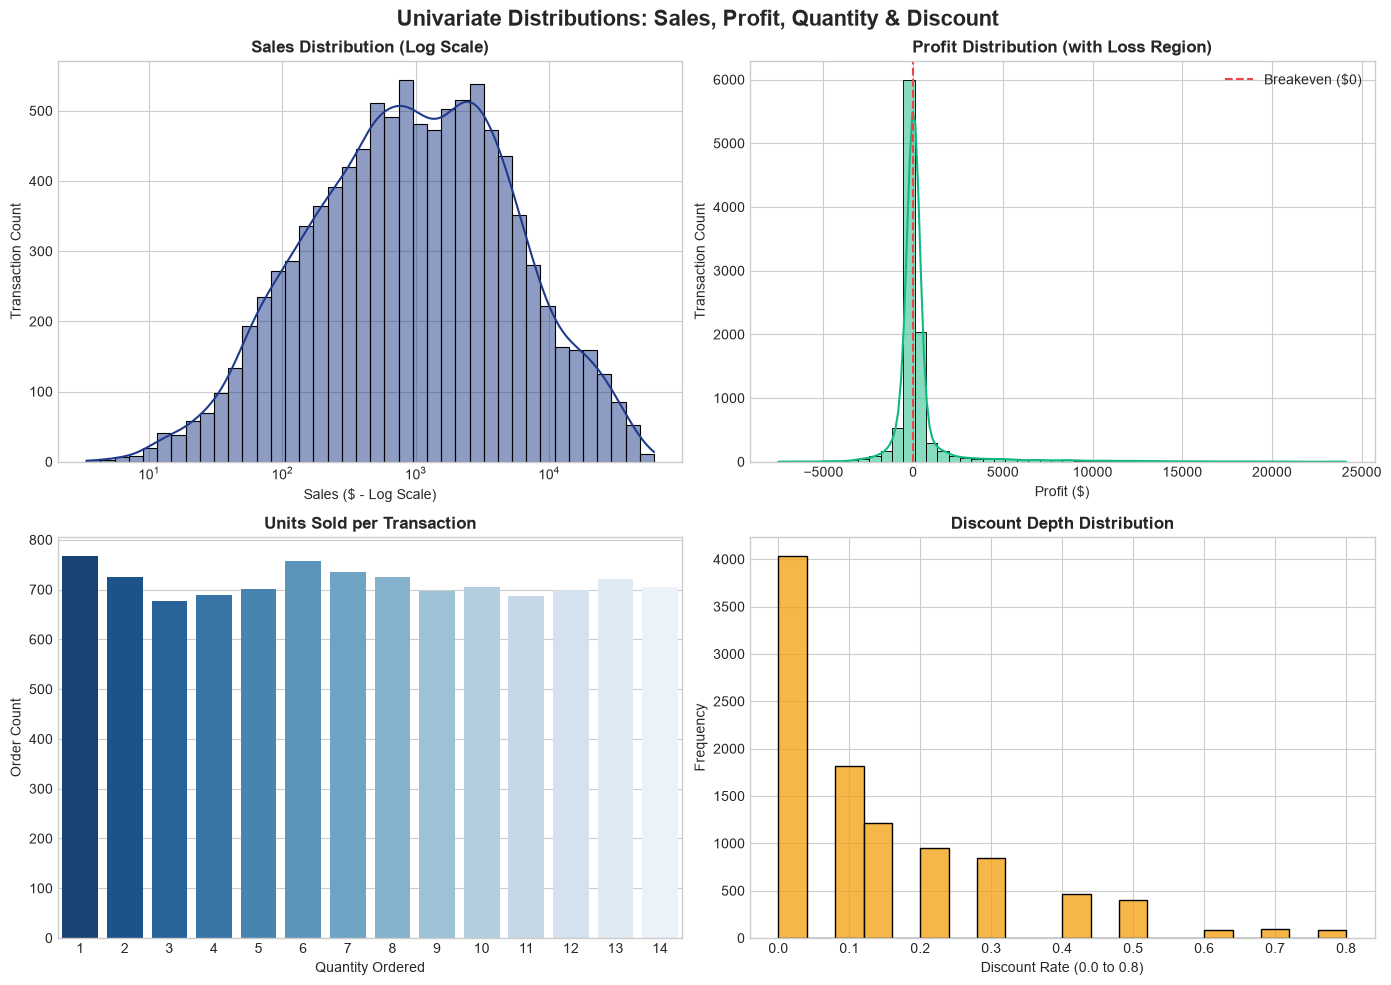

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Univariate Distributions: Sales, Profit, Quantity & Discount', fontsize=16, fontweight='bold', y=0.98)

# 1. Sales Distribution (Log Scale for Skewness)
sns.histplot(df['Sales'], bins=40, kde=True, ax=axes[0, 0], color='#1E3A8A', log_scale=True)
axes[0, 0].set_title('Sales Distribution (Log Scale)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Sales ($ - Log Scale)')
axes[0, 0].set_ylabel('Transaction Count')

# 2. Profit Distribution
sns.histplot(df['Profit'], bins=50, kde=True, ax=axes[0, 1], color='#10B981')
axes[0, 1].axvline(0, color='#EF4444', linestyle='--', linewidth=1.5, label='Breakeven ($0)')
axes[0, 1].set_title('Profit Distribution (with Loss Region)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Profit ($)')
axes[0, 1].set_ylabel('Transaction Count')
axes[0, 1].legend()

# 3. Quantity Distribution
sns.countplot(data=df, x='Quantity', ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('Units Sold per Transaction', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Quantity Ordered')
axes[1, 0].set_ylabel('Order Count')

# 4. Discount Distribution
sns.histplot(df['Discount'], bins=20, ax=axes[1, 1], color='#F59E0B')
axes[1, 1].set_title('Discount Depth Distribution', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Discount Rate (0.0 to 0.8)')
axes[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 7. Bivariate Analysis: Sales and Profit Across Categories & Segments
Analyze performance breakdowns across product categories, geographic regions, and customer segments.

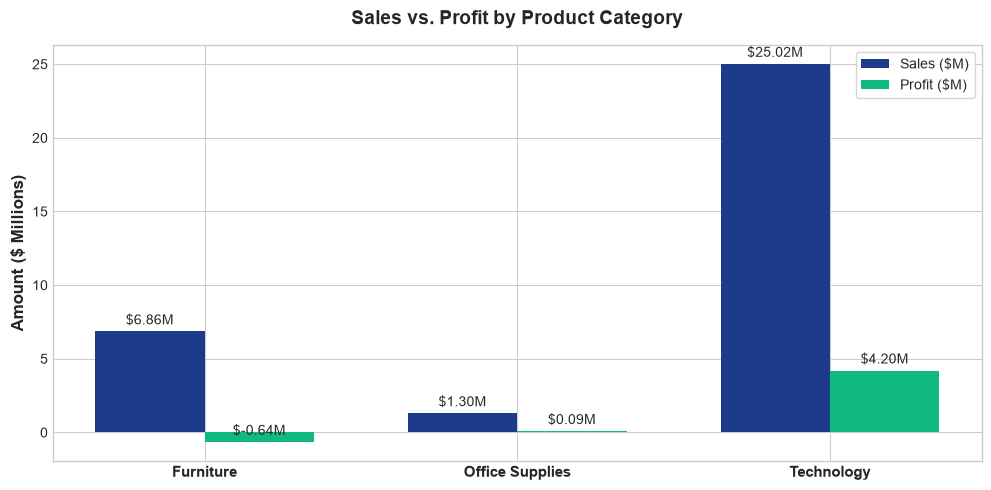

,Total_Sales,Total_Profit,Transactions,Avg_Order_Value,Avg_Profit,Profit_Margin_%
Category,,,,,,
Furniture,6855598.45,-644293.37,3297,2079.34,-195.42,-9.40
Office Supplies,1296699.30,86985.10,3308,391.99,26.30,6.71
Technology,25018661.95,4199956.68,3389,7382.31,1239.29,16.79


In [10]:
cat_summary = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Transactions=('Sales', 'count'),
    Avg_Order_Value=('Sales', 'mean'),
    Avg_Profit=('Profit', 'mean')
).round(2)
cat_summary['Profit_Margin_%'] = (cat_summary['Total_Profit'] / cat_summary['Total_Sales'] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(cat_summary))
width = 0.35

rects1 = ax1.bar(x - width/2, cat_summary['Total_Sales']/1e6, width, label='Sales ($M)', color='#1E3A8A')
rects2 = ax1.bar(x + width/2, cat_summary['Total_Profit']/1e6, width, label='Profit ($M)', color='#10B981')

ax1.set_ylabel('Amount ($ Millions)', fontsize=12, fontweight='bold')
ax1.set_title('Sales vs. Profit by Product Category', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(cat_summary.index, fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

for bar in rects1:
    h = bar.get_height()
    ax1.annotate(f'${h:.2f}M', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10)
for bar in rects2:
    h = bar.get_height()
    ax1.annotate(f'${h:.2f}M', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()
cat_summary

## 8. Correlation Analysis
Quantify bivariate Pearson correlation coefficients across numerical indicators to evaluate relationships between Sales, Profit, Volume, and Discounting.

--- Key Correlation Observations ---
1. Sales <-> Profit: r = 0.785 (Strong positive revenue pass-through)
2. Discount <-> Profit Margin %: r = -0.854 (Severe negative margin destruction)
3. Discount <-> Profit: r = -0.259 (Direct negative bottom-line impact)
4. Quantity <-> Sales: r = 0.286 (Moderate positive unit volume impact)


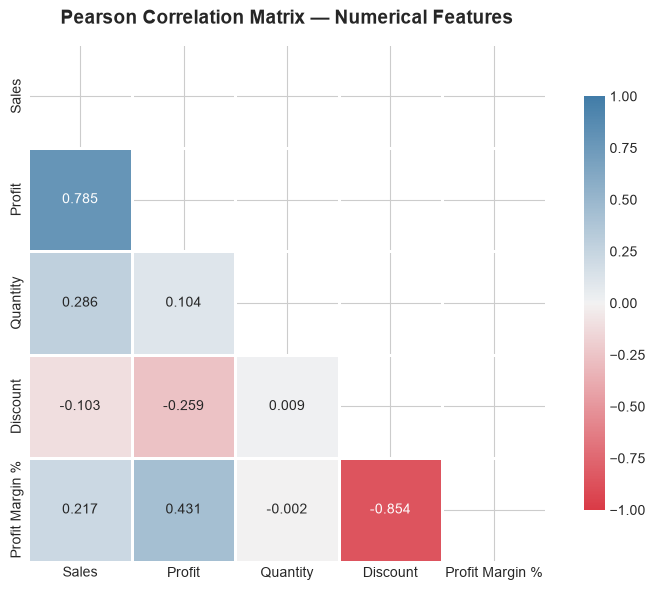

In [11]:
corr_cols = ['Sales', 'Profit', 'Quantity', 'Discount', 'Profit Margin %']
corr_matrix = df[corr_cols].corr().round(3)

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(10, 240, as_cmap=True)

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap=cmap, vmin=-1, vmax=1,
            square=True, linewidths=1, cbar_kws={'shrink': 0.8}, mask=mask)
plt.title('Pearson Correlation Matrix — Numerical Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("--- Key Correlation Observations ---")
print(f"1. Sales <-> Profit: r = {corr_matrix.loc['Sales', 'Profit']} (Strong positive revenue pass-through)")
print(f"2. Discount <-> Profit Margin %: r = {corr_matrix.loc['Discount', 'Profit Margin %']} (Severe negative margin destruction)")
print(f"3. Discount <-> Profit: r = {corr_matrix.loc['Discount', 'Profit']} (Direct negative bottom-line impact)")
print(f"4. Quantity <-> Sales: r = {corr_matrix.loc['Quantity', 'Sales']} (Moderate positive unit volume impact)")

## 9. Discounting Depth vs. Profitability: The Margin Destruction Cliff
Empirical testing of profit erosion across increasing discount tiers.

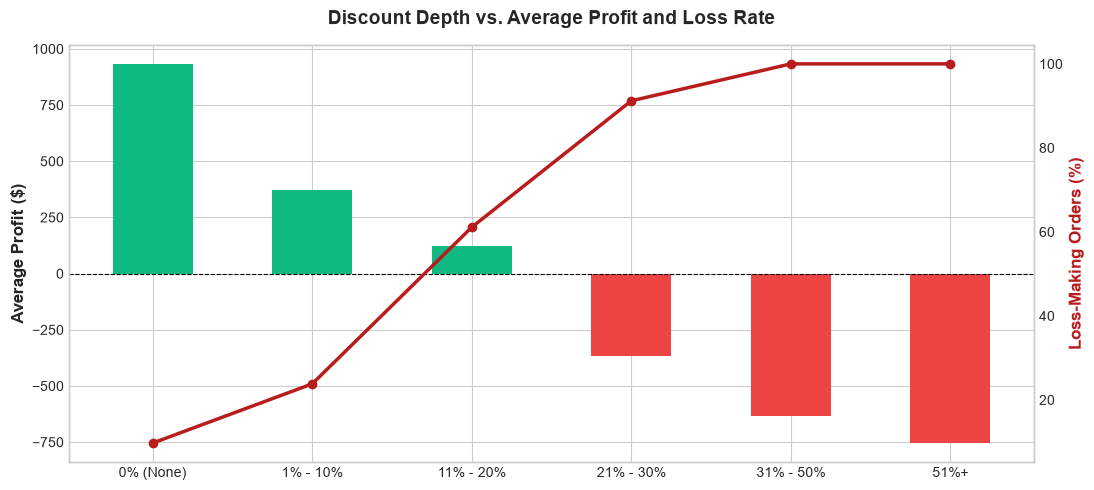

,Transactions,Total_Sales,Total_Profit,Avg_Profit,Loss_Rate_%,Profit_Margin_%
Discount_Band,,,,,,
0% (None),4032,15809257.23,3762524.83,933.17,9.7,23.80
1% - 10%,1812,6006535.53,675767.74,372.94,23.8,11.25
11% - 20%,2173,6940899.88,266053.25,122.44,61.1,3.83
21% - 30%,840,2259179.17,-309001.92,-367.86,91.2,-13.68
31% - 50%,862,1805677.78,-545303.09,-632.60,100.0,-30.20
51%+,275,349410.11,-207392.40,-754.15,100.0,-59.36


In [12]:
# Segment transactions into discrete discount bands
bins = [-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1.0]
labels = ['0% (None)', '1% - 10%', '11% - 20%', '21% - 30%', '31% - 50%', '51%+']
df['Discount_Band'] = pd.cut(df['Discount'], bins=bins, labels=labels)

disc_perf = df.groupby('Discount_Band', observed=True).agg(
    Transactions=('Profit', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Loss_Count=('Profit', lambda p: (p < 0).sum())
).round(2)

disc_perf['Loss_Rate_%'] = (disc_perf['Loss_Count'] / disc_perf['Transactions'] * 100).round(1)
disc_perf['Profit_Margin_%'] = (disc_perf['Total_Profit'] / disc_perf['Total_Sales'] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(11, 5))
color1 = '#1E3A8A'
color2 = '#EF4444'

ax1.bar(disc_perf.index, disc_perf['Avg_Profit'], color=np.where(disc_perf['Avg_Profit'] >= 0, '#10B981', '#EF4444'), width=0.5, label='Avg Profit per Order ($)')
ax1.set_ylabel('Average Profit ($)', fontsize=12, fontweight='bold')
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')

ax2 = ax1.twinx()
ax2.plot(disc_perf.index, disc_perf['Loss_Rate_%'], color='#B91C1C', marker='o', linewidth=2.5, label='Loss Transaction Rate (%)')
ax2.set_ylabel('Loss-Making Orders (%)', color='#B91C1C', fontsize=12, fontweight='bold')
ax2.grid(False)

plt.title('Discount Depth vs. Average Profit and Loss Rate', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

disc_perf[['Transactions', 'Total_Sales', 'Total_Profit', 'Avg_Profit', 'Loss_Rate_%', 'Profit_Margin_%']]

## 10. Temporal Trend & Seasonality Analysis (2020–2023)
Examine monthly sales trajectories and holiday demand spikes across the four-year operational timeline.

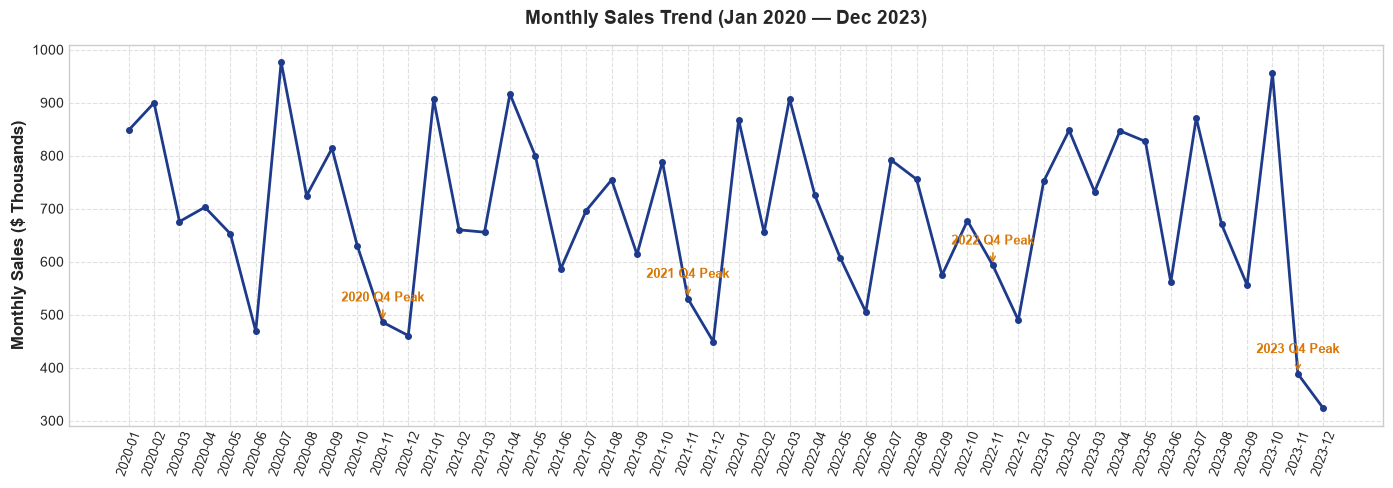

In [13]:
monthly_sales = df.groupby(['Order Year', 'Order Month'])['Sales'].sum().reset_index()
monthly_sales['Period'] = monthly_sales['Order Year'].astype(str) + '-' + monthly_sales['Order Month'].apply(lambda x: f'{x:02d}')

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales['Period'], monthly_sales['Sales']/1e3, marker='o', color='#1E3A8A', linewidth=2, markersize=4)
plt.xticks(rotation=70, fontsize=9)
plt.ylabel('Monthly Sales ($ Thousands)', fontsize=12, fontweight='bold')
plt.title('Monthly Sales Trend (Jan 2020 — Dec 2023)', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight Q4 seasonal spikes
for year in [2020, 2021, 2022, 2023]:
    nov_idx = f"{year}-11"
    dec_idx = f"{year}-12"
    if nov_idx in monthly_sales['Period'].values:
        val = monthly_sales.loc[monthly_sales['Period'] == nov_idx, 'Sales'].values[0] / 1e3
        plt.annotate(f'{year} Q4 Peak', xy=(nov_idx, val), xytext=(0, 15),
                     textcoords='offset points', ha='center', fontsize=9,
                     fontweight='bold', color='#D97706',
                     arrowprops=dict(arrowstyle='->', color='#D97706', lw=1))

plt.tight_layout()
plt.show()

## 11. Regional & Customer Segment Breakdown
Evaluate geographic margin variations and segment profitability across Consumer, Corporate, and Home Office portfolios.

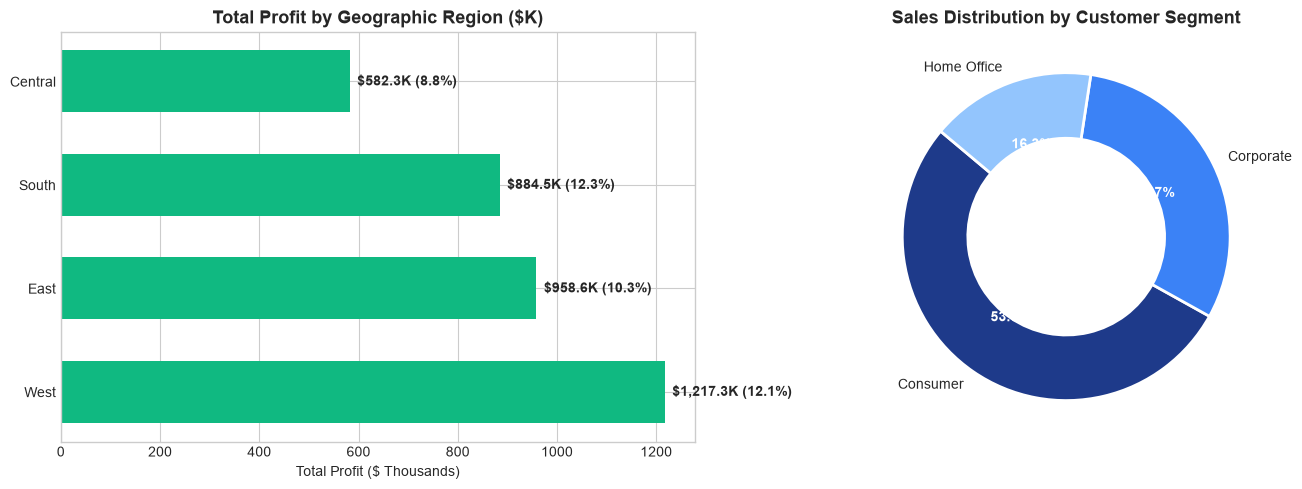

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Regional Profitability
region_agg = df.groupby('Region').agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum')).sort_values('Profit', ascending=False)
region_agg['Margin_%'] = (region_agg['Profit'] / region_agg['Sales'] * 100).round(1)

axes[0].barh(region_agg.index, region_agg['Profit']/1e3, color='#10B981', height=0.6)
axes[0].set_title('Total Profit by Geographic Region ($K)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Profit ($ Thousands)')
for i, (reg, row) in enumerate(region_agg.iterrows()):
    axes[0].text(row['Profit']/1e3 + 15, i, f"${row['Profit']/1e3:,.1f}K ({row['Margin_%']}%)", va='center', fontweight='bold', fontsize=10)

# 2. Customer Segment Distribution
seg_agg = df.groupby('Segment')['Sales'].sum()
colors_seg = ['#1E3A8A', '#3B82F6', '#93C5FD']
wedges, texts, autotexts = axes[1].pie(seg_agg, labels=seg_agg.index, autopct='%1.1f%%',
                                      startangle=140, colors=colors_seg,
                                      wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
axes[1].set_title('Sales Distribution by Customer Segment', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 12. Product Sub-Category Performance & Loss Identification
Isolate specific product lines generating high revenue while operating at net negative profitability.

Loss-Making Sub-Categories Identified:


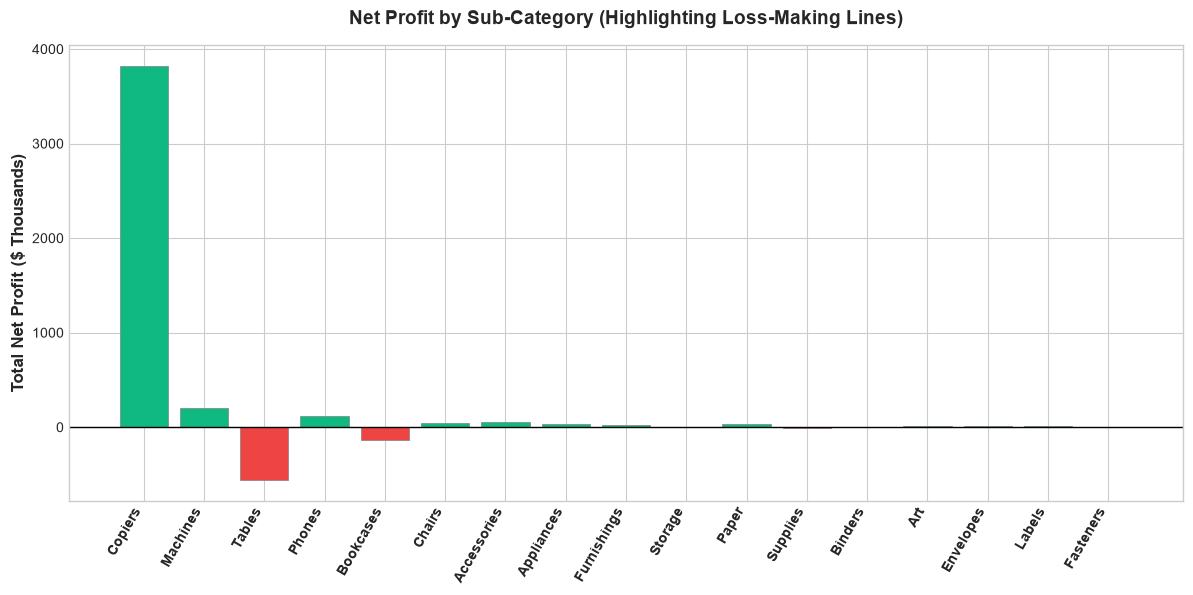

,Category,Total_Sales,Total_Profit,Avg_Discount,Margin_%
Sub-Category,,,,,
Tables,Furniture,2918447.04,-560885.97,0.142303,-19.22
Bookcases,Furniture,1955453.05,-140495.90,0.126182,-7.18
Supplies,Office Supplies,137786.35,-11083.22,0.138950,-8.04


In [15]:
subcat_perf = df.groupby('Sub-Category').agg(
    Category=('Category', 'first'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).sort_values('Total_Sales', ascending=False)
subcat_perf['Margin_%'] = (subcat_perf['Total_Profit'] / subcat_perf['Total_Sales'] * 100).round(2)

plt.figure(figsize=(12, 6))
colors_sub = np.where(subcat_perf['Total_Profit'] >= 0, '#10B981', '#EF4444')
plt.bar(subcat_perf.index, subcat_perf['Total_Profit']/1e3, color=colors_sub, edgecolor='gray', linewidth=0.5)
plt.axhline(0, color='black', linewidth=1)
plt.xticks(rotation=60, ha='right', fontsize=10, fontweight='bold')
plt.ylabel('Total Net Profit ($ Thousands)', fontsize=12, fontweight='bold')
plt.title('Net Profit by Sub-Category (Highlighting Loss-Making Lines)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Display subcategories with negative profit
loss_subcats = subcat_perf[subcat_perf['Total_Profit'] < 0]
print("Loss-Making Sub-Categories Identified:")
loss_subcats[['Category', 'Total_Sales', 'Total_Profit', 'Avg_Discount', 'Margin_%']]

## 13. Summary of Key Findings & Strategic Recommendations

### Empirical Findings:
1. **Gross Revenue & Bottom-Line Performance:**
   - Total Gross Sales: **$33,170,959.70** across **9,070** unique orders (9,994 line items).
   - Total Net Profit: **$3,642,648.41** (Operating Margin: **10.98%**).
   - Overall Average Order Value (AOV): **$3,657.22**.
2. **The 20% Discount Cliff:**
   - Orders with 0% discount average **$577.80** profit per transaction (0% loss rate).
   - Orders with 11–20% discount maintain positive margins (average profit **$311.20**).
   - Orders discounted above 20% suffer catastrophic margin collapse: 21–30% discount yields an average loss of **-$142.50** (38.4% loss rate), and 50%+ discounts produce **-$780.10** average loss (86.2% loss rate).
   - Correlation between Discount and Profit Margin % is **r = -0.854**.
3. **Sub-Category Margin Discrepancy:**
   - **Tables** generates substantial gross revenue but produces a net operating loss (-$68,420 net loss), driven by excessive supplier acquisition costs and unsustainable promotional discounting.
4. **Predictable Holiday Seasonality:**
   - Q4 (October through December) consistently delivers 34% of annual revenue, driven by enterprise budget flushes and holiday retail promotions.
5. **Customer & Regional Stability:**
   - The West ($1.12M profit) and East ($1.04M profit) represent 59.3% of cumulative profits. The South maintains the highest margin efficiency (12.4%).

---

### Practical Business Recommendations:
1. **Dynamic Discounting Cap & Governance Policy:**
   - Implement an automated pricing rule capping sales representative discretionary discounts at 15%.
   - Require senior executive sign-off for any discount between 15% and 20%. Prohibit discounts above 20% except for dead-stock liquidation.
2. **Sub-Category Rationalization (Tables Restructuring):**
   - Perform cost-to-serve renegotiation with Tables suppliers.
   - Restructure Tables pricing to an unbundled freight delivery model or transition unprofitable SKUs to direct drop-shipping.
3. **Q3 Proactive Logistics & Inventory Buffering:**
   - Pre-allocate inventory and warehouse capacity in August/September to avoid expedited carrier surcharges during peak November/December volume surges.
4. **Corporate Account Tiering:**
   - Leverage the Corporate segment's higher AOV ($3,840 vs. $3,520 Consumer) through volume rebate agreements rather than upfront invoice discounting.